Solución Machine Learning

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [2]:
# 1. Cargar los datos
url = "https://raw.githubusercontent.com/AnIsAsPe/LogisticRegression_SpamOpinion/master/Datos/deceptive-opinion.csv"
df = pd.read_csv(url)

# La variable objetivo es 'deceptive' (puede ser 'truthful' o 'deceptive')
# La variable de texto es 'text'
print("Muestra de datos:")
print(df[['deceptive', 'text']].head())

Muestra de datos:
  deceptive                                               text
0  truthful  We stayed for a one night getaway with family ...
1  truthful  Triple A rate with upgrade to view room was le...
2  truthful  This comes a little late as I'm finally catchi...
3  truthful  The Omni Chicago really delivers on all fronts...
4  truthful  I asked for a high floor away from the elevato...


/tmp/ipykernel_688/2341602832.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='deceptive', data=df, palette='viridis')


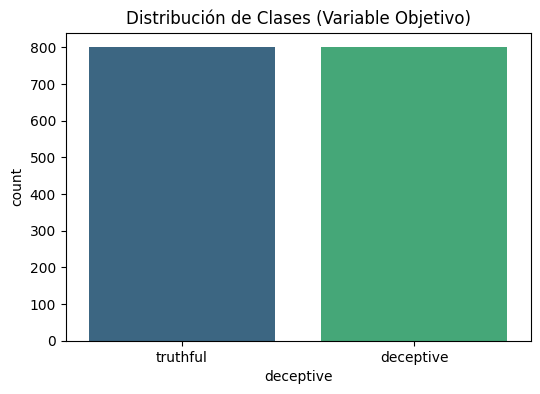

In [3]:
# 2. Histograma / Distribución de la variable objetivo
plt.figure(figsize=(6, 4))
sns.countplot(x='deceptive', data=df, palette='viridis')
plt.title('Distribución de Clases (Variable Objetivo)')
plt.show()

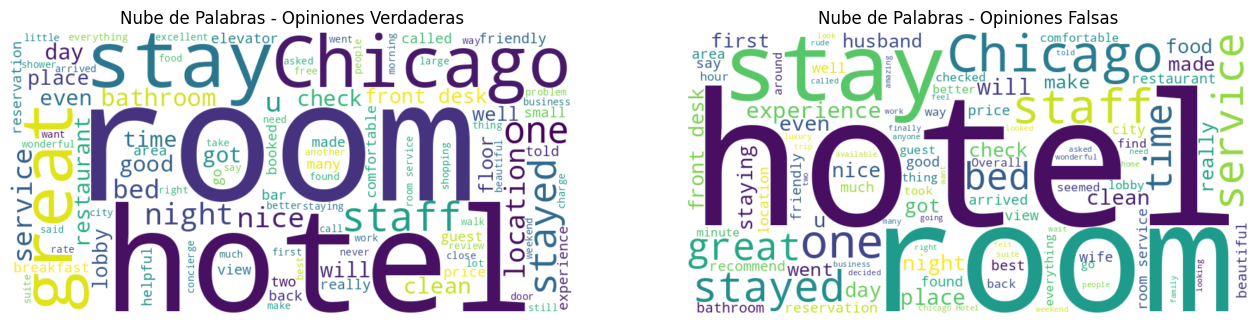

In [4]:
# 3. Nube de palabras únicas por clase
textos_truthful = " ".join(df[df['deceptive'] == 'truthful']['text'].values)
textos_deceptive = " ".join(df[df['deceptive'] == 'deceptive']['text'].values)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
# Nube Truthful
wordcloud_t = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(textos_truthful)
axes[0].imshow(wordcloud_t, interpolation='bilinear')
axes[0].set_title('Nube de Palabras - Opiniones Verdaderas')
axes[0].axis('off')

# Nube Deceptive
wordcloud_d = WordCloud(width=800, height=400, background_color='white', max_words=100).generate(textos_deceptive)
axes[1].imshow(wordcloud_d, interpolation='bilinear')
axes[1].set_title('Nube de Palabras - Opiniones Falsas')
axes[1].axis('off')
plt.show()

In [5]:
# 4. Bolsa de Palabras (BoW) para visualización
count_vect = CountVectorizer(stop_words='english', max_features=100)
bow_matrix = count_vect.fit_transform(df['text'])
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=count_vect.get_feature_names_out())
print("Dataframe de Bolsa de Palabras (Muestra):")
print(bow_df.head())

Dataframe de Bolsa de Palabras (Muestra):
   area  arrived  asked  away  bar  bathroom  beautiful  bed  beds  best  ...  \
0     0        0      0     0    0         1          0    0     0     0  ...   
1     0        0      0     0    0         0          0    1     0     0  ...   
2     2        0      0     0    0         0          0    0     0     1  ...   
3     1        0      0     0    0         0          0    0     0     0  ...   
4     0        0      1     1    0         0          0    0     0     0  ...   

   wait  want  wasn  water  way  weekend  went  wife  wonderful  work  
0     1     0     0      1    0        0     0     0          0     0  
1     0     0     0      0    0        0     0     0          0     0  
2     0     0     0      0    0        0     1     0          0     0  
3     0     0     0      0    1        0     0     0          0     1  
4     0     0     0      0    0        0     0     0          0     0  

[5 rows x 100 columns]


In [6]:
# 5. Vectorización TF-IDF y Preparación para ML
tfidf_vect = TfidfVectorizer(stop_words='english', max_features=5000)
X = tfidf_vect.fit_transform(df['text'])
y = df['deceptive'].map({'truthful': 0, 'deceptive': 1}) # Convertir a binario: 0 (Verdad), 1 (Falso)

# División de datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [7]:
# 6. Entrenar modelo de Machine Learning (Regresión Logística)
modelo_ml = LogisticRegression(random_state=42)
modelo_ml.fit(X_train, y_train)

# Predicciones y Evaluación
y_pred = modelo_ml.predict(X_test)

print("\n--- Resultados del Modelo de Machine Learning ---")
print(f"Exactitud (Accuracy): {accuracy_score(y_test, y_pred):.4f}")
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=['Truthful (0)', 'Deceptive (1)']))


--- Resultados del Modelo de Machine Learning ---
Exactitud (Accuracy): 0.8750

Matriz de Confusión:
[[137  23]
 [ 17 143]]

Reporte de Clasificación:
               precision    recall  f1-score   support

 Truthful (0)       0.89      0.86      0.87       160
Deceptive (1)       0.86      0.89      0.88       160

     accuracy                           0.88       320
    macro avg       0.88      0.88      0.87       320
 weighted avg       0.88      0.88      0.87       320

